<a href="https://colab.research.google.com/github/THE5NEON/Python-Labs/blob/main/%D0%9B%D0%A04_%D0%A2%D0%BE%D1%87%D0%B5%D0%BD%D1%8E%D0%BA_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


**Виконав:** Точенюк Ярослав, група 4-9.

CSV завантажується з публічної копії: https://github.com/ameenmanna8824/DATASETS/blob/main/CarPrice_Assignment.csv. Якщо мережеве завантаження недоступне, додайте CarPrice_Assignment.csv до середовища Colab.

## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid')
url = 'https://raw.githubusercontent.com/ameenmanna8824/DATASETS/main/CarPrice_Assignment.csv'
local = Path('CarPrice_Assignment.csv')
df = pd.read_csv(local if local.exists() else url)
assert {'car_ID','symboling','price'}.issubset(df.columns)
print('Об’єкти, стовпці:', df.shape, '| Ціль: price')
print('Кількість предикторів без ID:', df.shape[1]-2)
display(df.head(), df.dtypes.to_frame('Тип'), df.describe(include='all').T)
print('Висновок: ціна є числовою цільовою змінною; дані містять числові й категоріальні ознаки.')

Об’єкти, стовпці: (205, 26) | Ціль: price
Кількість предикторів без ID: 24


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


,Тип
car_ID,int64
symboling,int64
CarName,object
fueltype,object
aspiration,object
doornumber,object
carbody,object
drivewheel,object
enginelocation,object
wheelbase,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_ID,205.0,NaN,NaN,NaN,103.0,59.322565,1.0,52.0,103.0,154.0,205.0
symboling,205.0,NaN,NaN,NaN,0.834146,1.245307,-2.0,0.0,1.0,2.0,3.0
CarName,205,147,peugeot 504,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fueltype,205,2,gas,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspiration,205,2,std,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
doornumber,205,2,four,115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carbody,205,5,sedan,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drivewheel,205,3,fwd,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enginelocation,205,2,front,202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wheelbase,205.0,NaN,NaN,NaN,98.756585,6.021776,86.6,94.5,97.0,102.4,120.9


Висновок: ціна є числовою цільовою змінною; дані містять числові й категоріальні ознаки.


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [2]:
quality = pd.DataFrame({'Пропуски':df.isna().sum(),'Унікальні':df.nunique()})
display(quality)
print('Повні дублікати:', df.duplicated().sum())
print('Дублікати без ID:', df.drop(columns='car_ID').duplicated().sum())
print('Висновок: ID не характеризує зміст автомобіля; дублікати оцінюємо також без нього. Рядки автоматично не видаляємо.')

,Пропуски,Унікальні
car_ID,0,205
symboling,0,6
CarName,0,147
fueltype,0,2
aspiration,0,2
doornumber,0,2
carbody,0,5
drivewheel,0,3
enginelocation,0,2
wheelbase,0,53


Повні дублікати: 0
Дублікати без ID: 0
Висновок: ID не характеризує зміст автомобіля; дублікати оцінюємо також без нього. Рядки автоматично не видаляємо.


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [3]:
car_ids = df['car_ID'].copy()
data = df.drop(columns='car_ID').copy()
assert 'car_ID' not in data.columns
print('Висновок: ID збережено окремо для таблиць прогнозів, але виключено з предикторів.')

Висновок: ID збережено окремо для таблиць прогнозів, але виключено з предикторів.


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


,Асиметрія
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


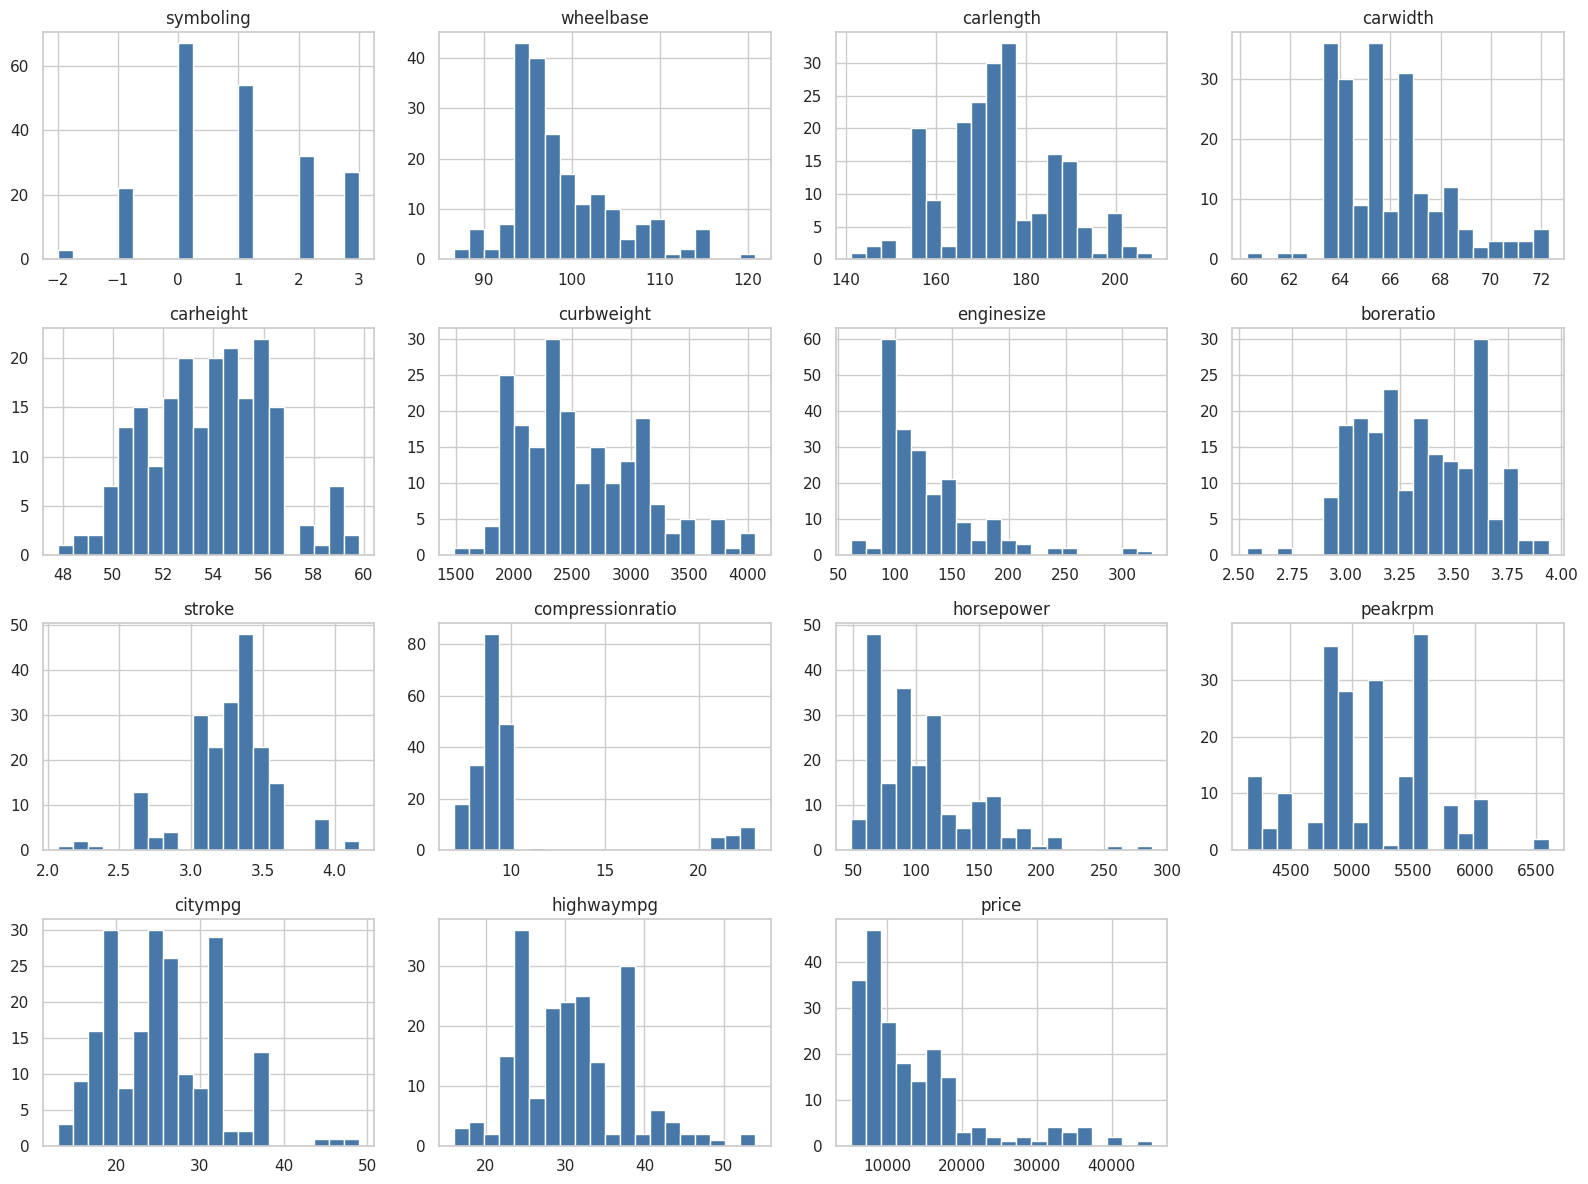

Найбільша асиметрія: compressionratio, enginesize, price
Висновок: |асиметрія| характеризує відхилення від симетрії. Цей описовий огляд не визначає параметрів передобробки.


In [4]:
numeric = data.select_dtypes(include='number')
skew_all = numeric.skew().sort_values(key=abs,ascending=False)
display(skew_all.to_frame('Асиметрія'))
numeric.hist(bins=20, figsize=(16,12), color='#4878a8', edgecolor='white')
plt.tight_layout(); plt.show()
print('Найбільша асиметрія:', ', '.join(skew_all.head(3).index))
print('Висновок: |асиметрія| характеризує відхилення від симетрії. Цей описовий огляд не визначає параметрів передобробки.')

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [5]:
from sklearn.model_selection import train_test_split
X = data.drop(columns='price'); y = data['price']
X_train_raw, X_test_raw, y_train, y_test, id_train, id_test = train_test_split(X,y,car_ids,test_size=0.2,random_state=42)
assert not set(id_train).intersection(id_test)
print('Train:', X_train_raw.shape, 'Test:', X_test_raw.shape)
print('Висновок: тест відокремлено до визначення параметрів передобробки.')

Train: (164, 24) Test: (41, 24)
Висновок: тест відокремлено до визначення параметрів передобробки.


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [6]:
continuous = [c for c in X_train_raw.select_dtypes(include='number') if c != 'symboling']
q1 = X_train_raw[continuous].quantile(.25); q3 = X_train_raw[continuous].quantile(.75)
iqr = q3-q1
lower = q1-1.5*iqr; upper = q3+1.5*iqr
# За нульового IQR не обрізаємо ознаку до константи.
lower = lower.mask(iqr==0,-np.inf); upper = upper.mask(iqr==0,np.inf)
counts = ((X_train_raw[continuous]<lower)|(X_train_raw[continuous]>upper)).sum()
display(pd.DataFrame({'Нижня межа':lower,'Верхня межа':upper,'Викиди train':counts}))
X_train = X_train_raw.copy(); X_test = X_test_raw.copy()
for frame in (X_train,X_test):
    frame[continuous] = frame[continuous].clip(lower=lower,upper=upper,axis=1)
print('Висновок: обмеження за IQR train зберігає всі рядки; price не змінюється.')

,Нижня межа,Верхня межа,Викиди train
wheelbase,83.1000,113.5000,6
carlength,141.8875,207.9875,0
carwidth,60.4250,70.4250,10
carheight,46.4625,60.9625,0
curbweight,998.6250,4103.6250,0
enginesize,33.5000,205.5000,7
boreratio,2.5650,4.1250,1
stroke,2.6600,3.8600,16
compressionratio,7.4000,10.6000,20
horsepower,4.7500,182.7500,7


Висновок: обмеження за IQR train зберігає всі рядки; price не змінюється.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


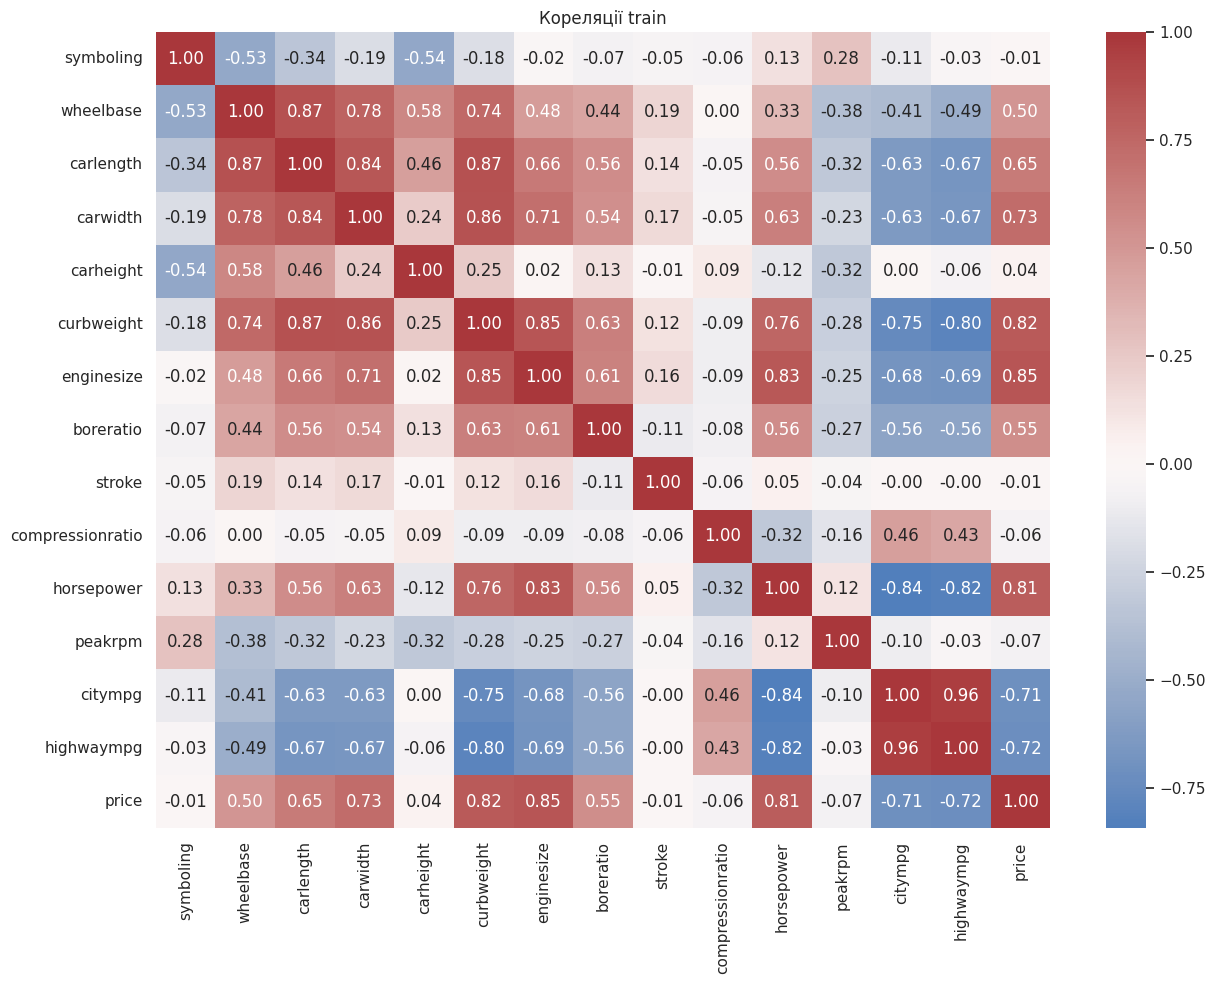

,Ознака 1,Ознака 2,r
0,wheelbase,carlength,0.867043
1,carlength,curbweight,0.865988
2,carwidth,curbweight,0.858047
3,citympg,highwaympg,0.963620


Видалені ознаки: ['carwidth', 'citympg', 'carlength']
Висновок: відбір зменшує мультиколінеарність; пріоритет мають ознаки з сильнішим зв’язком із price у train.


In [7]:
corr = X_train.select_dtypes(include='number').assign(price=y_train).corr()
plt.figure(figsize=(13,10)); sns.heatmap(corr,annot=True,fmt='.2f',cmap='vlag',center=0); plt.title('Кореляції train'); plt.tight_layout(); plt.show()
features = list(corr.columns.drop('price'))
pairs = [(a,b,corr.loc[a,b]) for i,a in enumerate(features) for b in features[i+1:] if abs(corr.loc[a,b])>.85]
display(pd.DataFrame(pairs,columns=['Ознака 1','Ознака 2','r']))
ordered = sorted(features,key=lambda c: abs(corr.loc[c,'price']) if pd.notna(corr.loc[c,'price']) else -1,reverse=True)
keep=[]; drop=[]
for c in ordered:
    if any(abs(corr.loc[c,k])>.85 for k in keep): drop.append(c)
    else: keep.append(c)
X_train = X_train.drop(columns=drop); X_test = X_test.drop(columns=drop)
print('Видалені ознаки:',drop)
print('Висновок: відбір зменшує мультиколінеарність; пріоритет мають ознаки з сильнішим зв’язком із price у train.')

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
continuous = [c for c in X_train.select_dtypes(include='number') if c!='symboling']
discrete = ['symboling'] if 'symboling' in X_train else []
categorical = list(X_train.select_dtypes(exclude='number').columns)
num_pipe = Pipeline([('impute',SimpleImputer(strategy='median')),('power',PowerTransformer(method='yeo-johnson',standardize=False)),('scale',StandardScaler())])
cat_pipe = Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('continuous',num_pipe,continuous),('symboling',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),discrete),('category',cat_pipe,categorical)],sparse_threshold=0)
print('Неперервні:',continuous,'\nДискретні:',discrete,'\nКатегоріальні:',categorical)
print('Висновок: одна схема обробки для всіх моделей; невідомі категорії ігноруються без помилки.')

Неперервні: ['wheelbase', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg'] 
Дискретні: ['symboling'] 
Категоріальні: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']
Висновок: одна схема обробки для всіх моделей; невідомі категорії ігноруються без помилки.


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [9]:
from sklearn.base import clone
transformed = clone(num_pipe).fit_transform(X_train[continuous])
skew_before = X_train[continuous].skew(); skew_after = pd.DataFrame(transformed,columns=continuous).skew()
comparison = pd.DataFrame({'До':skew_before,'Після':skew_after})
display(comparison)
print('Середня абсолютна асиметрія до/після:',skew_before.abs().mean(),skew_after.abs().mean())
print('Висновок:', 'Середня асиметрія зменшилась.' if skew_after.abs().mean()<skew_before.abs().mean() else 'Середня асиметрія не зменшилась.')

,До,Після
wheelbase,0.935764,0.020429
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188


Середня абсолютна асиметрія до/після: 0.4289286810153238 0.022904360829783282
Висновок: Середня асиметрія зменшилась.


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [10]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor
estimators = {'Linear Regression':LinearRegression(),'Ridge':Ridge(alpha=1),'Lasso':Lasso(alpha=10,max_iter=50000),'Random Forest':RandomForestRegressor(n_estimators=200,random_state=42,n_jobs=-1),'Gradient Boosting':GradientBoostingRegressor(random_state=42),'SVR':TransformedTargetRegressor(regressor=SVR(C=10,epsilon=.1),transformer=StandardScaler())}
models = {name:Pipeline([('preprocess',clone(preprocessor)),('model',est)]) for name,est in estimators.items()}
print('Висновок: побудовано шість моделей; для SVR ціль додатково масштабується лише за train і повертається до початкових одиниць.')

Висновок: побудовано шість моделей; для SVR ціль додатково масштабується лише за train і повертається до початкових одиниць.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [11]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
predictions={}; rows=[]
for name, model in models.items():
    model.fit(X_train,y_train)
    pred = model.predict(X_test); predictions[name]=pred
    rows.append({'Модель':name,'R²':r2_score(y_test,pred),'MAE':mean_absolute_error(y_test,pred),'MSE':mean_squared_error(y_test,pred),'MAPE (%)':100*mean_absolute_percentage_error(y_test,pred),'R² train':model.score(X_train,y_train)})
results=pd.DataFrame(rows).set_index('Модель').sort_values('R²',ascending=False)
display(results.round(3))
print('Висновок: найкраща за R²:',results.index[0],'; найменша MAE:',results.MAE.idxmin())

,R²,MAE,MSE,MAPE (%),R² train
Модель,,,,,
Random Forest,0.954,1367.501,3.648690e+06,9.949,0.986
Gradient Boosting,0.934,1660.090,5.244394e+06,12.366,0.992
SVR,0.904,1828.062,7.552061e+06,17.382,0.991
Ridge,0.789,2758.385,1.665988e+07,23.911,0.963
Lasso,0.775,2608.846,1.774613e+07,19.380,0.971
Linear Regression,0.530,4184.432,3.711970e+07,30.634,0.993


Висновок: найкраща за R²: Random Forest ; найменша MAE: Random Forest


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Logistic Regression оцінює ймовірності класів, а не неперервну ціну. Прогнозування price є задачею регресії. Усі шість обраних моделей повертають числовий прогноз ціни, тому відповідають постановці задачі.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


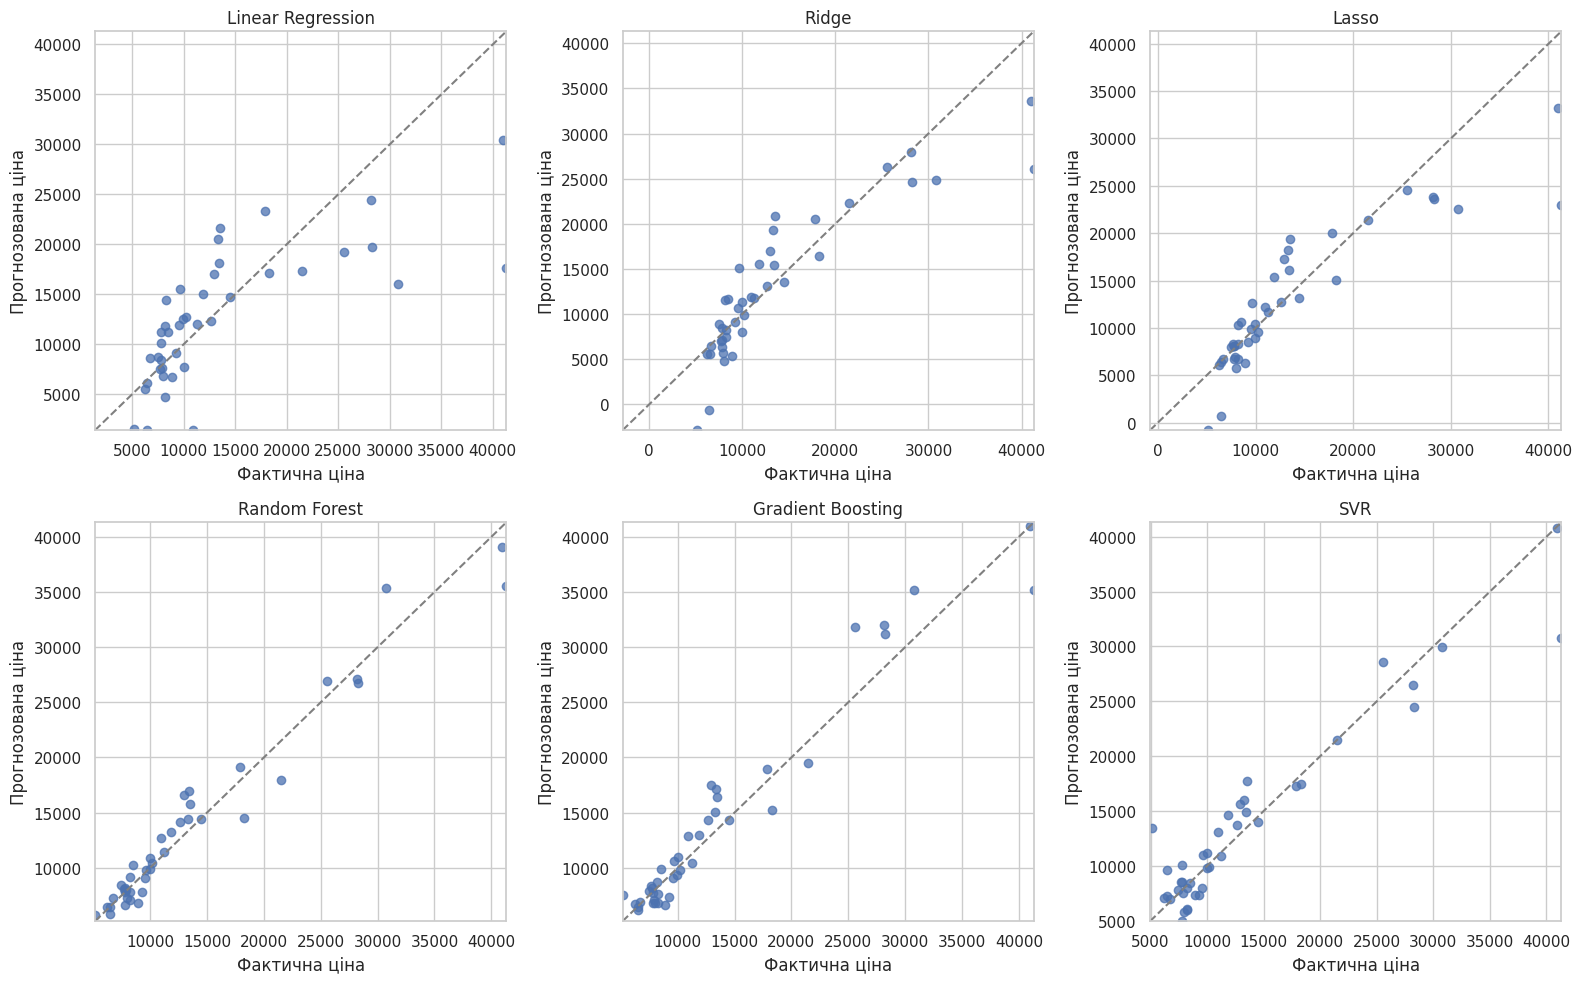

Linear Regression — максимальне абсолютне відхилення: 23695.35
Ridge — максимальне абсолютне відхилення: 15267.17
Lasso — максимальне абсолютне відхилення: 18327.07
Random Forest — максимальне абсолютне відхилення: 5765.25
Gradient Boosting — максимальне абсолютне відхилення: 6283.83
SVR — максимальне абсолютне відхилення: 10541.73
Висновок: точки ближче до діагоналі відповідають точнішим прогнозам; великі відхилення особливо впливають на MSE.


In [12]:
fig, axes = plt.subplots(2,3,figsize=(16,10))
for ax,(name,pred) in zip(axes.flat,predictions.items()):
    lo=min(y_test.min(),pred.min()); hi=max(y_test.max(),pred.max())
    ax.scatter(y_test,pred,alpha=.75); ax.plot([lo,hi],[lo,hi],'--',color='gray'); ax.set(title=name,xlabel='Фактична ціна',ylabel='Прогнозована ціна'); ax.set_xlim(lo,hi); ax.set_ylim(lo,hi)
plt.tight_layout(); plt.show()
for name,pred in predictions.items():
    print(name,'— максимальне абсолютне відхилення:',round(np.max(np.abs(y_test.to_numpy()-pred)),2))
print('Висновок: точки ближче до діагоналі відповідають точнішим прогнозам; великі відхилення особливо впливають на MSE.')

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [13]:
rf_table=pd.DataFrame({'car_ID':id_test,'Фактична ціна':y_test,'Прогнозована ціна':predictions['Random Forest']},index=y_test.index)
rf_table['Абсолютна помилка']=(rf_table['Фактична ціна']-rf_table['Прогнозована ціна']).abs()
rf_table['Абсолютна відсоткова помилка']=100*rf_table['Абсолютна помилка']/rf_table['Фактична ціна'].abs().replace(0,np.nan)
sample=rf_table.sample(10,random_state=42)
display(sample.round(2))
print('Висновок: середня абсолютна відсоткова помилка 10 авто:',round(sample['Абсолютна відсоткова помилка'].mean(),2),'%')

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка
25,26,6692.0,7242.46,550.45,8.23
175,176,9988.0,10928.84,940.84,9.42
147,148,10198.0,10466.21,268.21,2.63
16,17,41315.0,35549.75,5765.25,13.95
68,69,28248.0,26720.33,1527.67,5.41
146,147,7463.0,8405.92,942.92,12.63
143,144,9960.0,9898.08,61.92,0.62
84,85,14489.0,14408.73,80.27,0.55
194,195,12940.0,16551.88,3611.88,27.91
159,160,7788.0,7826.62,38.61,0.50


Висновок: середня абсолютна відсоткова помилка 10 авто: 8.19 %


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Підсумковий висновок формується за фактичними результатами після запуску наступної комірки.

In [14]:
best=results.iloc[0]
print(f'Найкраща за R²: {results.index[0]} (R²={best["R²"]:.4f}, MAE={best.MAE:.2f}, MSE={best.MSE:.2f}, MAPE={best["MAPE (%)"]:.2f}%).')
for metric in ['MAE','MSE','MAPE (%)']:
    print(f'Найменша {metric}: {results[metric].idxmin()} ({results[metric].min():.2f})')
gap=results['R² train']-results['R²']
print('Різниця R² train/test:',gap.round(3).to_dict())
print('Великий позитивний розрив може свідчити про перенавчання; для підтвердження потрібна крос-валідація.')
print('Передобробка обмежує викиди, усуває сильну кореляцію, масштабує числові та кодує категоріальні ознаки. Її окремий вплив потребує порівняння з моделями без передобробки.')

Найкраща за R²: Random Forest (R²=0.9538, MAE=1367.50, MSE=3648689.69, MAPE=9.95%).
Найменша MAE: Random Forest (1367.50)
Найменша MSE: Random Forest (3648689.69)
Найменша MAPE (%): Random Forest (9.95)
Різниця R² train/test: {'Random Forest': 0.032, 'Gradient Boosting': 0.058, 'SVR': 0.086, 'Ridge': 0.174, 'Lasso': 0.196, 'Linear Regression': 0.463}
Великий позитивний розрив може свідчити про перенавчання; для підтвердження потрібна крос-валідація.
Передобробка обмежує викиди, усуває сильну кореляцію, масштабує числові та кодує категоріальні ознаки. Її окремий вплив потребує порівняння з моделями без передобробки.


## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
